In [1]:
from pathlib import Path

from email_outreach.utils.constants import ROOT_FOLDER

# ============================== CONFIG ==============================
EXP_ROOT = ROOT_FOLDER / "experiments" / "test_set" / "1" / "contextual_bandit"

# display name -> folder with the experiment runs (order = plotting / table order)
EXPERIMENTS: dict[str, Path] = {
    "Baseline": EXP_ROOT / "true_baseline",
    "Forward-Pass Definition of 𝑓𝑗(𝑡)": EXP_ROOT / "forward_pass_f",
    "Negative Feedback via a Second SAE": EXP_ROOT / "negative_feedback",
    "Recency-Weighted Historic Rate 𝜙𝑗": EXP_ROOT / "recency_weighted_phi",
    "Variance-Based Definition of 𝑝𝑗": EXP_ROOT / "variance_based_p",
    "Factored Score with Scheduled Coefficients": EXP_ROOT / "factored_s_score",
}

REFERENCE = "Baseline"                          # deltas are computed vs. this experiment (None = no deltas)
N_POINTS = 101                                  # resolution of the recall/precision curves
HIGHLIGHT_X = [0.05, 0.15, 0.25, 0.35, 0.50, 0.75]   # points for the recall/precision tables
RECALL_TARGETS = [0.80, 0.90, 0.95]             # "x needed to reach recall >= target" table
ZOOM_X_MAX = 0.40                               # right edge of the zoomed plots
STD_DDOF = 0                                    # 0 = population std (as before), 1 = sample std
DECIMALS = 4
SAVE_DIR = None                                 # e.g. Path("figures") to also save PNGs
# ====================================================================

## Load experiments

In [2]:
from email_outreach.notes.experiment_summary import (
    load_experiments, show_summary_tables,
    plot_mean_curves, plot_recall_delta, plot_individual_runs, plot_auc,
)

results = load_experiments(EXPERIMENTS, n_points=N_POINTS, std_ddof=STD_DDOF, reference=REFERENCE)

Baseline: 100 runs loaded in 88s  (/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/experiments/test_set/1/contextual_bandit/true_baseline)
Forward-Pass Definition of 𝑓𝑗(𝑡): 100 runs loaded in 83s  (/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/experiments/test_set/1/contextual_bandit/forward_pass_f)
Negative Feedback via a Second SAE: 100 runs loaded in 79s  (/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/experiments/test_set/1/contextual_bandit/negative_feedback)
Recency-Weighted Historic Rate 𝜙𝑗: 100 runs loaded in 81s  (/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/experiments/test_set/1/contextual_bandit/recency_weighted_phi)
Variance-Based Definition of 𝑝𝑗: 100 runs loaded in 75s  (/home/tim4ik/main_code_base/python_projects/Active-

## Summary tables

In [3]:
show_summary_tables(results, highlight_x=HIGHLIGHT_X, recall_targets=RECALL_TARGETS,
                    reference=REFERENCE, decimals=DECIMALS)

### Recall AUC

,runs,AUC mean,AUC std,AUC min,AUC max,Δ AUC vs ref (pp)
Baseline,100.0,0.8914,0.0118,0.8717,0.9107,NaN
Forward-Pass Definition of 𝑓𝑗(𝑡),100.0,0.9088,0.0114,0.8787,0.9268,1.73
Negative Feedback via a Second SAE,100.0,0.9095,0.0110,0.8891,0.9279,1.81
Recency-Weighted Historic Rate 𝜙𝑗,100.0,0.9083,0.0104,0.8790,0.9261,1.68
Variance-Based Definition of 𝑝𝑗,100.0,0.9046,0.0104,0.8747,0.9215,1.31
Factored Score with Scheduled Coefficients,100.0,0.9033,0.0107,0.8718,0.9205,1.19


### Recall at selected points (mean ± std over runs; columns = x = 1 - quantile)

,0.05,0.15,0.25,0.35,0.50,0.75
Baseline,0.3588 ± 0.0782,0.8185 ± 0.0242,0.9236 ± 0.0125,0.9593 ± 0.0116,0.9745 ± 0.0080,0.9879 ± 0.0043
Forward-Pass Definition of 𝑓𝑗(𝑡),0.4512 ± 0.0472,0.8519 ± 0.0294,0.9380 ± 0.0190,0.9651 ± 0.0108,0.9755 ± 0.0080,0.9891 ± 0.0041
Negative Feedback via a Second SAE,0.4663 ± 0.0432,0.8507 ± 0.0307,0.9352 ± 0.0202,0.9647 ± 0.0109,0.9764 ± 0.0077,0.9895 ± 0.0040
Recency-Weighted Historic Rate 𝜙𝑗,0.4927 ± 0.0388,0.8396 ± 0.0251,0.9306 ± 0.0139,0.9623 ± 0.0106,0.9751 ± 0.0080,0.9889 ± 0.0042
Variance-Based Definition of 𝑝𝑗,0.4566 ± 0.0402,0.8341 ± 0.0263,0.9292 ± 0.0138,0.9621 ± 0.0106,0.9750 ± 0.0080,0.9888 ± 0.0042
Factored Score with Scheduled Coefficients,0.4430 ± 0.0402,0.8330 ± 0.0269,0.9294 ± 0.0137,0.9620 ± 0.0106,0.9750 ± 0.0080,0.9888 ± 0.0042


**Δ recall vs `Baseline` (pp)**

,0.05,0.15,0.25,0.35,0.50,0.75
Forward-Pass Definition of 𝑓𝑗(𝑡),9.24,3.33,1.45,0.58,0.10,0.12
Negative Feedback via a Second SAE,10.75,3.22,1.17,0.54,0.19,0.16
Recency-Weighted Historic Rate 𝜙𝑗,13.39,2.10,0.71,0.29,0.05,0.09
Variance-Based Definition of 𝑝𝑗,9.78,1.56,0.57,0.28,0.05,0.09
Factored Score with Scheduled Coefficients,8.42,1.45,0.58,0.27,0.05,0.08


... (2 outputs left out)

**Δ precision vs `Baseline` (pp)**

,0.05,0.15,0.25,0.35,0.50,0.75
Forward-Pass Definition of 𝑓𝑗(𝑡),8.67,1.05,0.28,0.08,0.01,0.01
Negative Feedback via a Second SAE,10.19,1.01,0.22,0.08,0.02,0.01
Recency-Weighted Historic Rate 𝜙𝑗,12.77,0.67,0.14,0.04,0.01,0.01
Variance-Based Definition of 𝑝𝑗,9.21,0.50,0.11,0.04,0.01,0.01
Factored Score with Scheduled Coefficients,7.91,0.46,0.12,0.04,0.00,0.01


### Smallest x at which the mean recall reaches the target (lower is better)

,recall ≥ 80%,recall ≥ 90%,recall ≥ 95%
Baseline,0.15,0.22,0.32
Forward-Pass Definition of 𝑓𝑗(𝑡),0.13,0.20,0.28
Negative Feedback via a Second SAE,0.13,0.20,0.29
Recency-Weighted Historic Rate 𝜙𝑗,0.13,0.21,0.31
Variance-Based Definition of 𝑝𝑗,0.14,0.21,0.31
Factored Score with Scheduled Coefficients,0.14,0.21,0.31


## Recall curves

/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/notes/experiment_summary.py:214: UserWarning: Glyph 119891 (\N{MATHEMATICAL ITALIC SMALL F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/notes/experiment_summary.py:214: UserWarning: Glyph 119895 (\N{MATHEMATICAL ITALIC SMALL J}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/notes/experiment_summary.py:214: UserWarning: Glyph 119905 (\N{MATHEMATICAL ITALIC SMALL T}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/notes/experiment_summary.py:214: UserWarning: Glyph 120601 (\N{MATHEMATICAL ITALIC PHI SYMBOL}) missing from font(s)

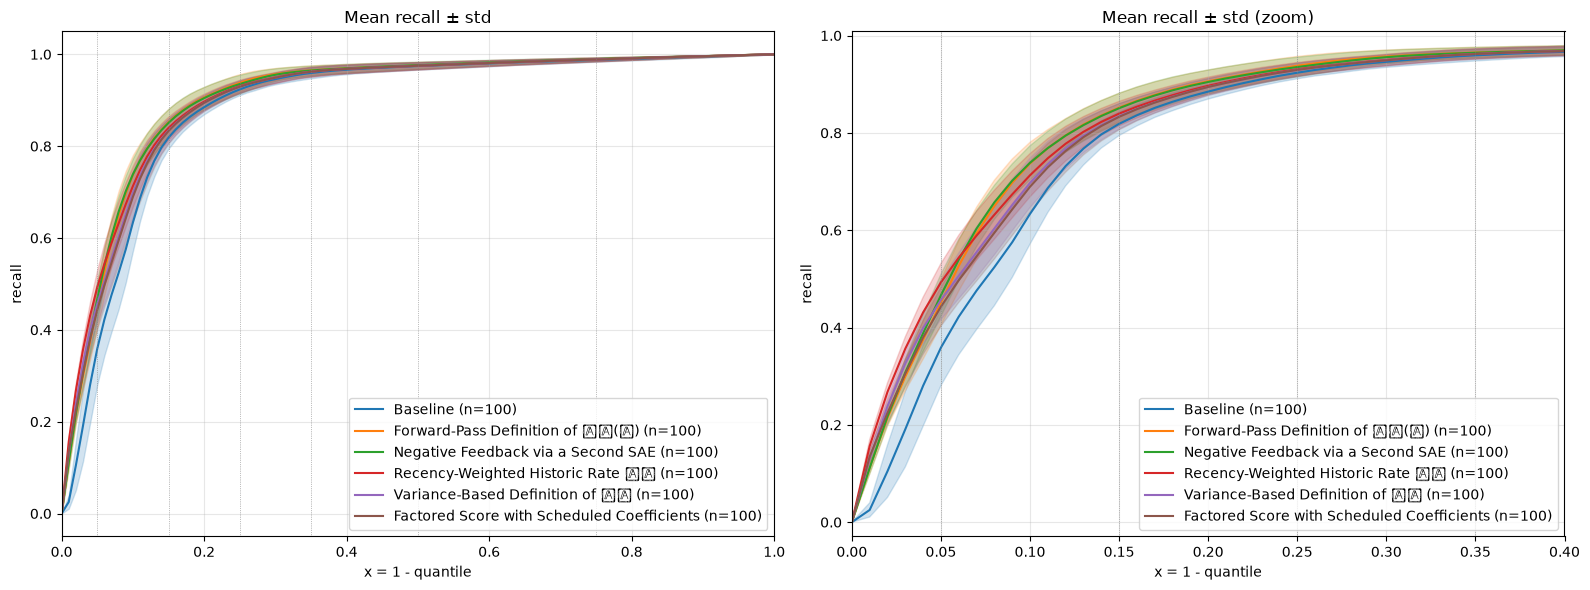

In [4]:
plot_mean_curves(results, kind="recall", highlight_x=HIGHLIGHT_X, zoom_x_max=ZOOM_X_MAX, save_dir=SAVE_DIR)

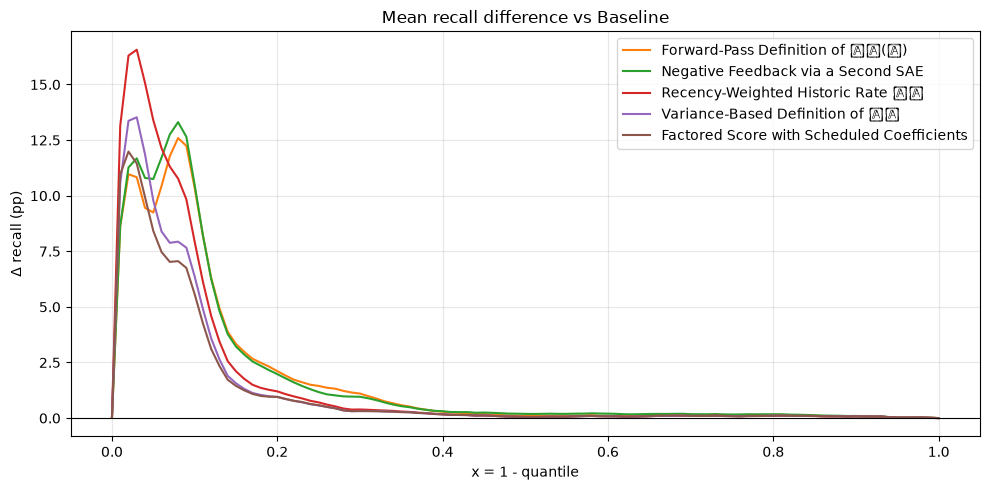

In [5]:
if REFERENCE is not None:
    plot_recall_delta(results, reference=REFERENCE, save_dir=SAVE_DIR)

## Individual runs overlaid

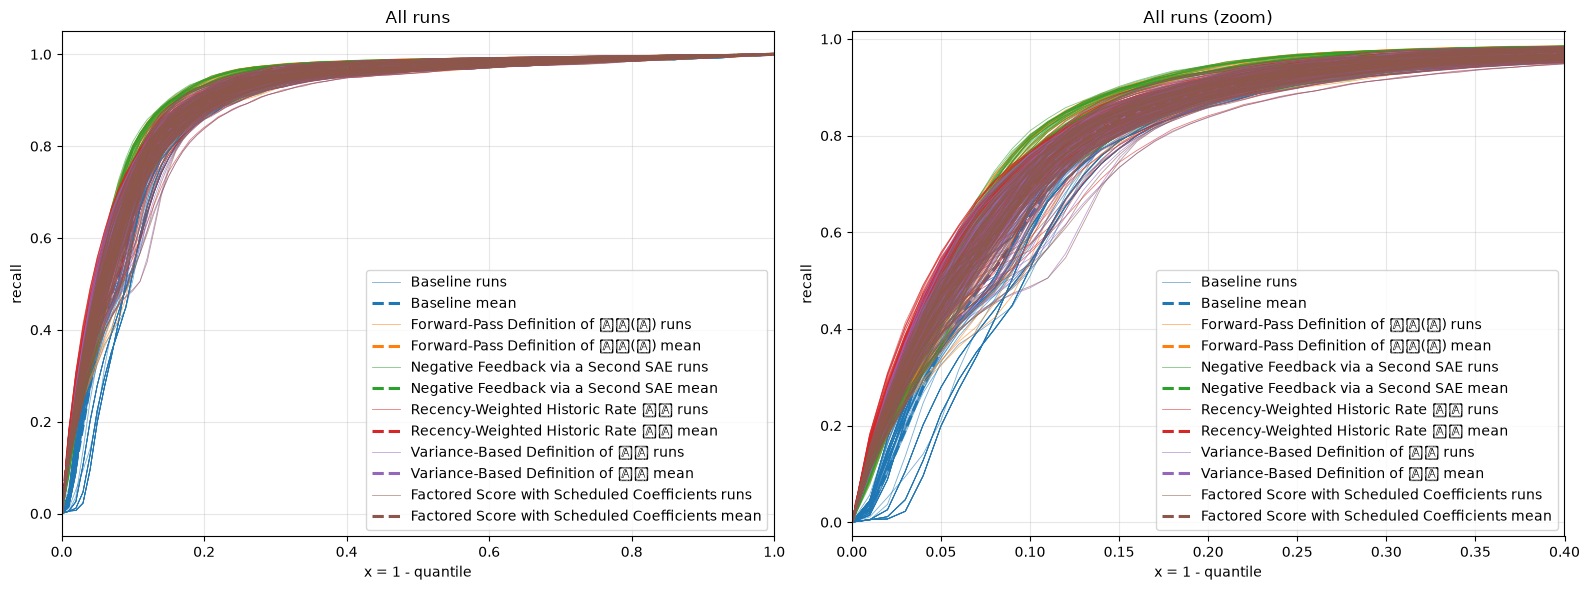

In [6]:
plot_individual_runs(results, kind="recall", zoom_x_max=ZOOM_X_MAX, save_dir=SAVE_DIR)

## Precision curves

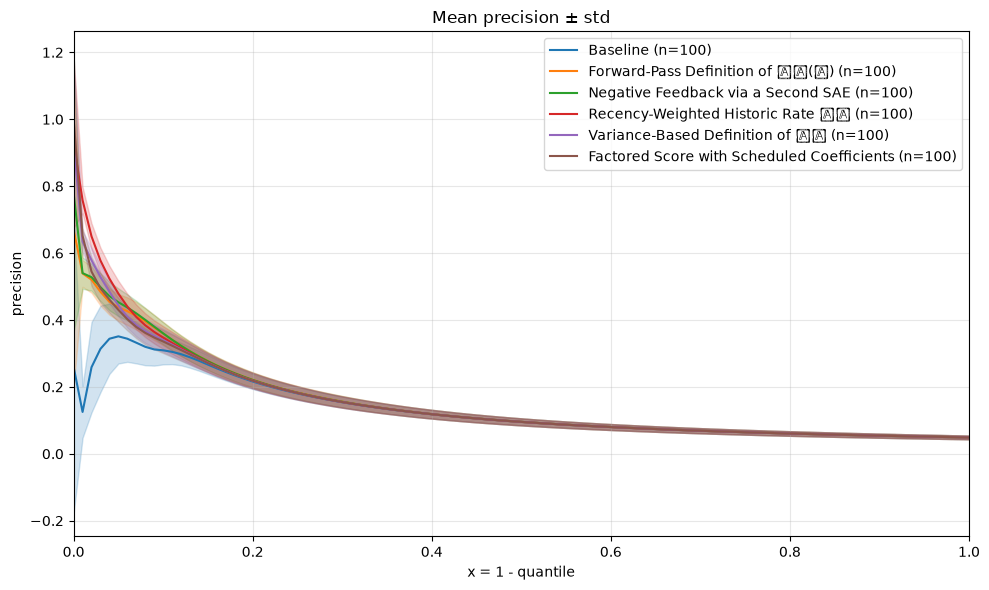

In [7]:
plot_mean_curves(results, kind="precision", save_dir=SAVE_DIR)

## Per-run AUC

/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/notes/experiment_summary.py:214: UserWarning: Glyph 119891 (\N{MATHEMATICAL ITALIC SMALL F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/notes/experiment_summary.py:214: UserWarning: Glyph 119895 (\N{MATHEMATICAL ITALIC SMALL J}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/notes/experiment_summary.py:214: UserWarning: Glyph 119905 (\N{MATHEMATICAL ITALIC SMALL T}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/notes/experiment_summary.py:214: UserWarning: Glyph 120601 (\N{MATHEMATICAL ITALIC PHI SYMBOL}) missing from font(s)

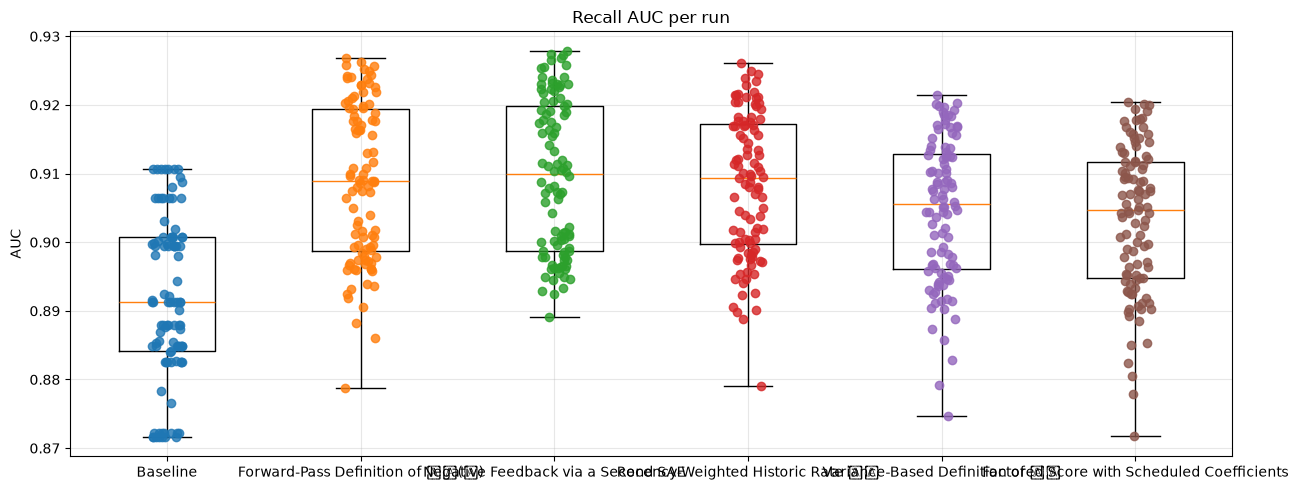

In [8]:
plot_auc(results, save_dir=SAVE_DIR)